<div align="center">

<img src="Logo_inpt.png" alt="INPT" width="160">


<br>
<h3 align="center">Institut National des Postes et Télécommunications (INPT)</h3>

<br><br>
<h1 align="center">Laaouafi Fatiha</h1>
<a href= "https://github.com/LAAOUAFIFATIHA/Math-for-AI/">Github link for this project</a>

</div>

In [15]:
import numpy as np
import time
import matplotlib.pyplot as plt

## Gauss without Row Permitation
**Gauss without Row Permutation** is a numerical method used to solve a system of linear equations by transforming its coefficient matrix into an upper triangular matrix, then applying back substitution to find the solution. It eliminates variables without exchanging rows. If a pivot is zero, the method fails.

In [4]:
def gauss(A, B, n):
    m = [[0.0] * n for _ in range(n)]
    x = [0.0] * n

    for k in range(n - 1):
        for i in range(k + 1, n):
            m[i][k] = A[i][k] / A[k][k]

            for j in range(k, n):
                A[i][j] = A[i][j] - m[i][k] * A[k][j]

            B[i] = B[i] - m[i][k] * B[k]

    x[n - 1] = B[n - 1] / A[n - 1][n - 1]

    for i in range(n - 2, -1, -1):
        summ = 0

        for j in range(i + 1, n):
            summ += A[i][j] * x[j]

        x[i] = (B[i] - summ) / A[i][i]

    return x

## Test Gauss without Row Permitation

We tested the function with different data sizes. As the amount of data increases, the execution time also increases significantly.

In [10]:
A = [[1, 2, 1],
     [2, 3, 1],
     [5, 6, 9]]
B = [0, -1, 20]
n = 3

debut = time.perf_counter()
X = gauss(A, B, n)
fin = time.perf_counter()

print("Ancienne taille :", n, "x", n)
print("Solution :", X)
print("Temps :", fin - debut, "secondes")


n = 1000
A = np.random.rand(n, n).tolist()
B = np.random.rand(n).tolist()

debut = time.perf_counter()
X = gauss(A, B, n)
fin = time.perf_counter()

print("\nNouvelle taille :", n, "x", n)
print("Temps :", fin - debut, "secondes")

Ancienne taille : 3 x 3
Solution : [1.0, -2.0, 3.0]
Temps : 0.0005115999992995057 secondes

Nouvelle taille : 1000 x 1000
Temps : 111.78690559999814 secondes


## Gauss with Row Permitation

In [12]:

def gauss_with_row_per(A, B, n):
    for k in range(n - 1):

        p = k
        for i in range(k + 1, n):
            if abs(A[i][k]) > abs(A[p][k]):
                p = i

        if A[p][k] == 0:
            return "Matrix is singular"

        A[k], A[p] = A[p], A[k]
        B[k], B[p] = B[p], B[k]

        for i in range(k + 1, n):
            m = A[i][k] / A[k][k]

            for j in range(k, n):
                A[i][j] -= m * A[k][j]

            B[i] -= m * B[k]

    if A[n - 1][n - 1] == 0:
        return "Matrix is singular"

    x = [0] * n

    for i in range(n - 1, -1, -1):
        summ = 0
        for j in range(i + 1, n):
            summ += A[i][j] * x[j]

        x[i] = (B[i] - summ) / A[i][i]

    return x


In [13]:
A = [[1, 2, 1],
     [2, 3, 1],
     [5, 6, 9]]
B = [0, -1, 20]
n = 3

debut = time.perf_counter()
X = gauss_with_row_per(A, B, n)
fin = time.perf_counter()

print("Ancienne taille :", n, "x", n)
print("Solution :", X)
print("Temps :", fin - debut, "secondes")


n = 1000
A = np.random.rand(n, n).tolist()
B = np.random.rand(n).tolist()

debut = time.perf_counter()
X = gauss_with_row_per(A, B, n)
fin = time.perf_counter()

print("\nNouvelle taille :", n, "x", n)
print("Temps :", fin - debut, "secondes")

Ancienne taille : 3 x 3
Solution : [1.0, -2.0, 3.0]
Temps : 0.00029709999944316223 secondes

Nouvelle taille : 1000 x 1000
Temps : 107.94474119999722 secondes


## Gauss with complete Pivoting

In [17]:

def gauss_with_complete_pivoting(A, B, n):
    perm = list(range(n))

    for k in range(n):
        p, q = k, k

        for i in range(k, n):
            for j in range(k, n):
                if abs(A[i][j]) > abs(A[p][q]):
                    p, q = i, j

        if abs(A[p][q]) < 1e-12:
            return "Matrix is singular"

        A[k], A[p] = A[p], A[k]
        B[k], B[p] = B[p], B[k]

        for i in range(n):
            A[i][k], A[i][q] = A[i][q], A[i][k]

        perm[k], perm[q] = perm[q], perm[k]

        for i in range(k + 1, n):
            m = A[i][k] / A[k][k]

            for j in range(k, n):
                A[i][j] -= m * A[k][j]

            B[i] -= m * B[k]

    x = [0.0] * n

    for i in range(n - 1, -1, -1):
        summ = sum(A[i][j] * x[j] for j in range(i + 1, n))
        x[i] = (B[i] - summ) / A[i][i]

    result = [0.0] * n
    for i in range(n):
        result[perm[i]] = x[i]

    return result


## Test Gauss with complete Pivoting

In [ ]:
A = [[1, 2, 1],
     [2, 3, 1],
     [5, 6, 9]]
B = [0, -1, 20]
n = 3

debut = time.perf_counter()
X = gauss_with_complete_pivoting(A, B, n)
fin = time.perf_counter()

print("Ancienne taille :", n, "x", n)
print("Solution :", X)
print("Temps :", fin - debut, "secondes")


n = 1000
A = np.random.rand(n, n).tolist()
B = np.random.rand(n).tolist()

debut = time.perf_counter()
X = gauss_with_complete_pivoting(A, B, n)
fin = time.perf_counter()

print("\nNouvelle taille :", n, "x", n)
print("Temps :", fin - debut, "secondes")

Ancienne taille : 3 x 3
Solution : [0.9999999999999991, -1.9999999999999993, 3.0]
Temps : 0.00026230000003124587 secondes


## Visualisation of performence

n = 3
Without pivoting:  0.000041 s
Partial pivoting:  0.000031 s
Complete pivoting: 0.000078 s
-----------------------------------
n = 10
Without pivoting:  0.000268 s
Partial pivoting:  0.000284 s
Complete pivoting: 0.000565 s
-----------------------------------
n = 25
Without pivoting:  0.003412 s
Partial pivoting:  0.002366 s
Complete pivoting: 0.007099 s
-----------------------------------
n = 50
Without pivoting:  0.030692 s
Partial pivoting:  0.027541 s
Complete pivoting: 0.037482 s
-----------------------------------
n = 100
Without pivoting:  0.131056 s
Partial pivoting:  0.120080 s
Complete pivoting: 0.227364 s
-----------------------------------
n = 200
Without pivoting:  1.042123 s
Partial pivoting:  0.674605 s
Complete pivoting: 1.508914 s
-----------------------------------
n = 500
Without pivoting:  14.490561 s
Partial pivoting:  13.381646 s
Complete pivoting: 30.260417 s
-----------------------------------


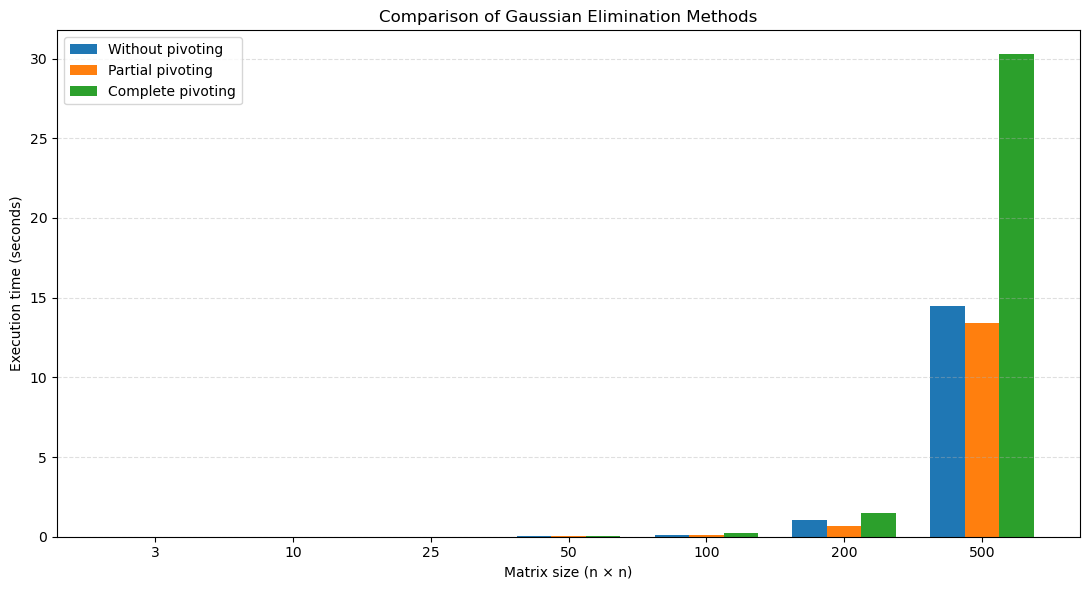

In [18]:
sizes = [3, 10, 25, 50, 100, 200,500]

times_without = []
times_with = []
times_complete = []

for n in sizes:
    A = np.random.rand(n, n) + n * np.eye(n)
    B = np.random.rand(n)

    A = A.tolist()
    B = B.tolist()

    start = time.perf_counter()
    gauss([row.copy() for row in A], B.copy(), n)
    times_without.append(time.perf_counter() - start)

    start = time.perf_counter()
    gauss_with_row_per(
        [row.copy() for row in A], B.copy(), n
    )
    times_with.append(time.perf_counter() - start)

    start = time.perf_counter()
    gauss_with_complete_pivoting(
        [row.copy() for row in A], B.copy(), n
    )
    times_complete.append(time.perf_counter() - start)

    print(f"n = {n}")
    print(f"Without pivoting:  {times_without[-1]:.6f} s")
    print(f"Partial pivoting:  {times_with[-1]:.6f} s")
    print(f"Complete pivoting: {times_complete[-1]:.6f} s")
    print("-" * 35)

x = np.arange(len(sizes))
width = 0.25

plt.figure(figsize=(11, 6))

plt.bar(x - width, times_without, width,
        label="Without pivoting")
plt.bar(x, times_with, width,
        label="Partial pivoting")
plt.bar(x + width, times_complete, width,
        label="Complete pivoting")

plt.xlabel("Matrix size (n × n)")
plt.ylabel("Execution time (seconds)")
plt.title("Comparison of Gaussian Elimination Methods")
plt.xticks(x, sizes)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

### Conclusion

Based on the execution time comparison, Gaussian elimination with partial pivoting is the best choice when computational efficiency is a priority. It generally offers a good balance between execution speed and numerical stability, while complete pivoting requires additional computations to search for the largest element in the remaining submatrix. Therefore, partial pivoting is a practical choice for solving linear systems efficiently and reliably.

In [ ]:
## end 